In [42]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import norm
from scipy.optimize import minimize

Numerical Maximum Likelihood Estimation

Some code for visualizing the objective function when using ```scipy.optimize.minimize```. Here, I am using it to visualize the negative log-likelihood of the Gaussian Distribution. One can also do this with the negative log-posterior

Some references:
- [Visualizing Optimization With Constraints](https://medium.com/data-science/introduction-to-optimization-constraints-with-scipy-7abd44f6de25)
- [Visualizing the MLE](https://barnesanalytics.com/maximum-likelihood/)

In [43]:
# Load in data
data_dir =  r"C:\Users\jluo1\Documents\repos\bayesian_statistics\data"
student_data = pd.read_csv(os.path.join(data_dir, "Student_Performance.csv"))
student_data.head(10)

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1,91.0
1,4,82,No,4,2,65.0
2,8,51,Yes,7,2,45.0
3,5,52,Yes,5,2,36.0
4,7,75,No,8,5,66.0
5,3,78,No,9,6,61.0
6,7,73,Yes,5,6,63.0
7,8,45,Yes,4,6,42.0
8,5,77,No,8,2,61.0
9,4,89,No,4,0,69.0


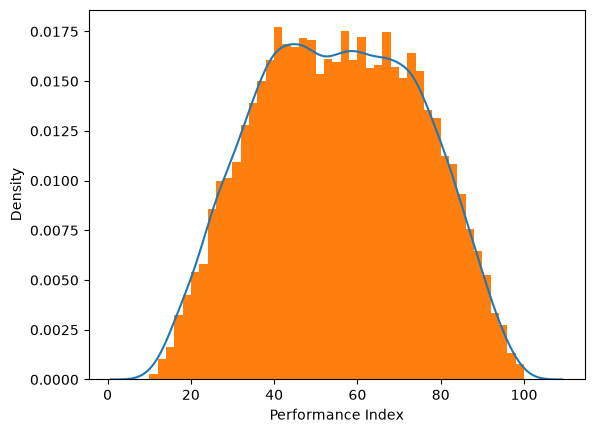

In [44]:
# Plots of performance index, looks bell curve-ish?
sns.kdeplot(data = student_data, x = "Performance Index", fill = False)
plt.hist(x = student_data["Performance Index"], density = True, bins = 45)
plt.show()

Optimization Success: True
Parameters Mu and Sigma: [55.22479366 19.21159959]


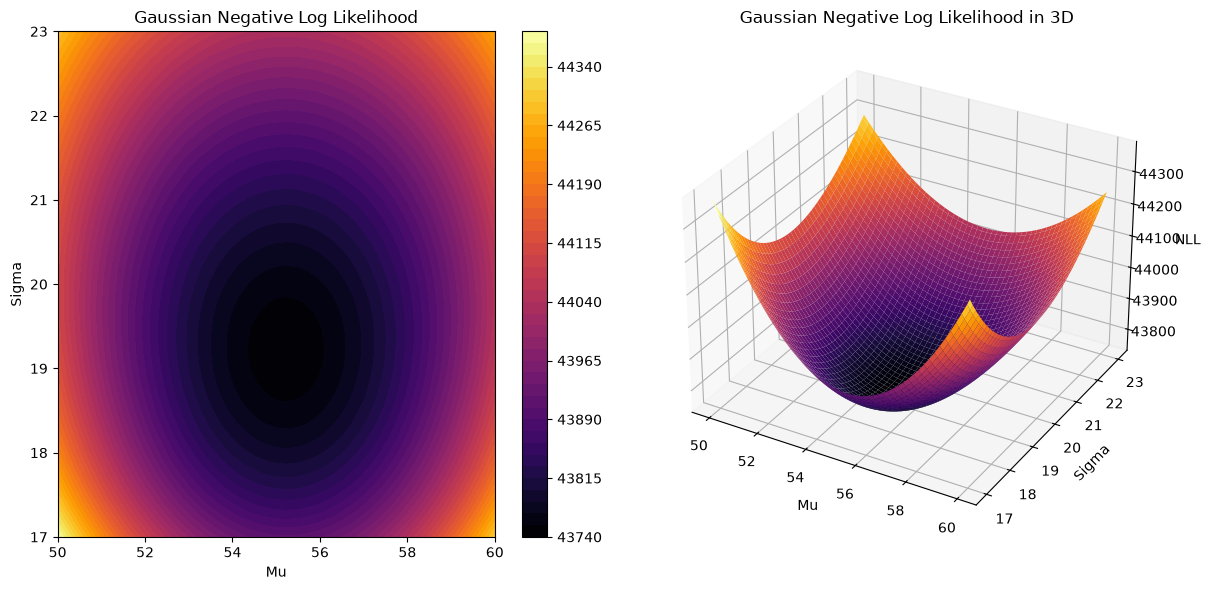

In [46]:
def normal_neg_ll(params, data):
    """
    Objective Function Negative Log Likelihood of Gaussian Distribution 
    """
    mu, sigma = params
    ll = np.sum(norm.logpdf(loc = mu, scale = sigma, x = data))
    return -ll

def plot_objective(mu_interval, sigma_interval, x, n_steps):
    """
    Plots the negative log-likelihood of the Gaussian Distribution in 3D
    """
    mu_min, mu_max = mu_interval
    sigma_min, sigma_max = sigma_interval

    if mu_min > mu_max or sigma_min > sigma_max:
        raise ValueError("Invalid parameter intervals")

    if sigma_min <= 0 or sigma_max <= 0:
        raise ValueError("Sigma must be non-negative")

    Mu, Sigma = np.meshgrid(np.linspace(mu_min, mu_max, n_steps),
                            np.linspace(sigma_min, sigma_max, n_steps))
    
    # Evaluate the negative log likelihood at mu and sigma across all x
    n_ll = np.array( [normal_neg_ll([m, s], x) for m,s in zip(Mu.flatten(), Sigma.flatten())] ).reshape(Mu.shape)

    fig = plt.figure(figsize = [12,6])

    axs = fig.add_subplot(1,2,1)
    contour = axs.contourf(Mu, Sigma, n_ll, levels = 50, cmap = "inferno")
    fig.colorbar(contour, ax = axs, orientation = "vertical")
    axs.set_xlabel("Mu")
    axs.set_ylabel("Sigma")
    axs.set_title("Gaussian Negative Log Likelihood")

    axs = fig.add_subplot(1,2,2, projection = "3d")
    axs.plot_surface(Mu, Sigma, n_ll, cmap = "inferno")
    axs.set_xlabel("Mu")
    axs.set_ylabel("Sigma")
    axs.set_zlabel("NLL")
    axs.set_title("Gaussian Negative Log Likelihood in 3D")

    plt.tight_layout()
    plt.show()


initial_guess = [10,10]
bounds = [(0, None), (1e-12, None)]
results = minimize(fun = normal_neg_ll,
                   x0 = initial_guess,
                   args = (student_data["Performance Index"], ),
                   bounds = bounds)
print(f"Optimization Success: {results.success}")
print(f"Parameters Mu and Sigma: {results.x}")

plot_objective([50,60], [17,23], student_data["Performance Index"], 100)
